# Tugas 2 Bagian C: Implementasi Digital Image Watermarking, Evaluasi Imperceptibility, dan Uji Robustness terhadap Serangan Citra

### Identitas Pengerjaan:
- **Mata Kuliah**: Pengolahan Citra Digital
- **Topik**: Digital Watermarking (Domain Spasial vs Domain Frekuensi), Imperceptibility, dan Robustness terhadap Serangan Manipulasi Citra
- **Penyusun**: Iman Dwi Satrio, Ahmad Zaidan

---

### Deskripsi Ruang Lingkup & Tujuan Pengerjaan:
Notebook ini disusun secara mandiri (*self-contained notebook*) untuk menyelesaikan seluruh tahapan pada **Bagian C (Digital Watermarking)**, yang mencakup:
1. **Pemuatan Gambar Utama Riil Alami (*Natural Host Image*)**: Memprioritaskan citra fotografi riil non-sintetis (khususnya citra wajah *in-the-wild* dari dataset DAiSEE hasil Bagian A) yang diskalakan ke resolusi standar $512 \times 512$ piksel dengan interpolasi `cv2.INTER_AREA` guna menjaga ketajaman tekstur alami.
2. **Implementasi Dua Teknik Watermarking Utama**:
   - **Teknik 1 (Domain Spasial)**: *Least Significant Bit* (LSB) Substitution pada kanal piksel inang.
   - **Teknik 2 (Domain Frekuensi / Transformasi)**: *Discrete Cosine Transform* (2D-DCT) berbasis partisi blok $8 \times 8$ dengan modulasi diferensial koefisien frekuensi menengah (*mid-frequency differential modulation*, $\alpha = 35.0$).
   - **Pembanding Kasatmata (*Visible Baseline*)**: *Alpha-Blending Watermarking* sebagai representasi taksonomi tanda air kasatmata (*visible watermark*).
3. **Evaluasi Kualitas Visual (*Imperceptibility Evaluation*)**:
   - Mengukur tingkat ketidakterlihatan watermark pada gambar utama menggunakan metrik objektif standar: *Peak Signal-to-Noise Ratio* (PSNR dalam dB) dan *Structural Similarity Index Measure* (SSIM).
   - Memetakan persebaran modifikasi intensitas piksel melalui *Absolute Residual Difference Map* (diperbesar 15x).
4. **Pengujian Ketahanan (*Robustness Evaluation*) terhadap Serangan Manipulasi Citra**:
   - **Serangan A**: Kompresi *lossy* JPEG dengan parameter kualitas $Q = 50$.
   - **Serangan B**: Penskalaan geometris (*Image Resizing* / *Downscale* $50\%$ resolusi dilanjutkan *Upscale* kembali ke $512 \times 512$ via interpolasi *bilinear*).
   - **Serangan C**: Pemotongan spasial (*Center Cropping* sebesar $15\%$ luas area tengah yang digantikan warna hitam).
5. **Pengukuran Tingkat Keberhasilan Ekstraksi Watermark**:
   - *Bit Error Rate* (BER): Mengukur rasio bit yang mengalami kesalahan rekonstruksi terhadap total bit watermark.
   - *Normalized Correlation* (NC): Mengukur derajat keserupaan dan korelasi silang ternormalisasi antara watermark asli dan watermark hasil ekstraksi.
6. **Analisis Segitiga Kompromi (*The Watermarking Trade-off Triangle*)**:
   - Membahas secara mendalam interaksi saling membatasi antara *Imperceptibility*, *Robustness*, dan *Capacity/Payload*, serta merumuskan rekomendasi praktis implementasi industri.



# Kajian Teoretis: Digital Image Watermarking

Digital watermarking adalah teknik penyisipan informasi sekunder (seperti logo kepemilikan, identitas hak cipta, cap waktu, atau tanda autentikasi) ke dalam sinyal multimedia atau gambar utama (*host media*) sedemikian rupa sehingga informasi tersebut dapat dideteksi atau diekstraksi kembali untuk tujuan verifikasi (Cox et al., 2007).


### 1. Taksonomi & Klasifikasi Digital Watermarking

Berdasarkan persepsi visual manusia (*human perceptibility*), sifat ketahanan (*robustness*), dan domain pemrosesan sinyal, watermarking diklasifikasikan ke dalam taksonomi berikut:

1. **Berdasarkan Visibilitas (Persepsi HVS)**:
   - **Visible Watermark**: Tanda air kasatmata yang sengaja dibuat tampak jelas pada citra (misal logo stasiun televisi atau watermark stok foto) untuk mencegah penggunaan tanpa izin secara psikologis. Memiliki distorsi visual tinggi ($PSNR < 35\text{ dB}$).
   - **Invisible Watermark**: Tanda air tak kasatmata yang disisipkan secara imperseptibel ke dalam data citra sehingga tidak disadari oleh mata manusia, namun dapat diekstraksi menggunakan algoritma komputasi khusus.
2. **Berdasarkan Ketahanan terhadap Distorsi (*Robustness*)**:
   - **Robust Watermarking**: Dirancang khusus untuk tahan terhadap berbagai manipulasi pemrosesan sinyal (kompresi lossy, penyaringan spasial, penskalaan, pemotongan, rotasi). Ditujukan untuk **perlindungan hak cipta (*copyright protection*)** dan pelacakan pembajakan (*fingerprinting*).
   - **Fragile Watermarking**: Sangat sensitif terhadap manipulasi sekecil apa pun. Jika citra mengalami alterasi sekecil 1 bit atau kuantisasi minimal, watermark akan rusak secara total. Ditujukan untuk **pemeriksaan integritas data (*tamper detection & image authentication*)**.
   - **Semi-Fragile Watermarking**: Toleran terhadap modifikasi non-destruktif minor (misal kompresi JPEG kualitas tinggi), namun rusak jika terjadi modifikasi konten semantik (misal penghapusan objek pada citra).
3. **Berdasarkan Domain Penyisipan (*Embedding Domain*)**:
   - **Domain Spasial (*Spatial Domain*)**: Modifikasi langsung dilakukan pada nilai intensitas piksel $f(x, y)$ (misal modulasi LSB).
   - **Domain Transformasi / Frekuensi (*Transform Domain*)**: Citra ditransformasikan ke domain frekuensi spasial (seperti DCT, DWT, atau DFT) sebelum koefisien frekuensinya dimodifikasi, kemudian dikembalikan ke domain spasial via transformasi balik (IDCT/IDWT).

---


---

### 2. Analogi Sederhana Konsep Watermarking

Agar konsep teknik watermarking mudah dipahami, kita dapat membayangkannya melalui analogi sederhana sehari-hari:
1. **Least Significant Bit (LSB)**:
   * **Analogi**: Seperti menyelipkan bisikan rahasia pada frekuensi nada yang paling lirih dalam sebuah lagu konser megah, atau menambahkan setitik debu halus pada lukisan besar.
   * Telinga atau mata manusia biasa tidak akan pernah menyadari perubahan mikro sebesar 1 tingkat keabuan ($2^0$) tersebut (imperceptibility sangat tinggi).
   * Namun, analogi ini juga menjelaskan mengapa LSB sangat rapuh: begitu lagu tersebut dikompresi menjadi MP3 atau lukisan difotokopi (seperti kompresi JPEG atau resize), nada lirih atau debu halus tadi akan langsung hilang tersapu bersih (*fragile*).
2. **Discrete Cosine Transform (DCT)**:
   * **Analogi**: Seperti membagi sebuah aransemen lagu menjadi tiga tingkatan nada:
     - **Nada Rendah (Low Frequency)**: Dentuman bass utama dan melodi dasar (latar belakang warna gambar yang lebar). Jika kita ubah di sini, suara lagu langsung fals dan terdengar jelas oleh pendengar (merusak estetika visual).
     - **Nada Tinggi (High Frequency)**: Suara gemerisik simbal yang sangat halus atau desis angin (detail tepi mikro dan noise). Jika lagu dikompresi, pemotong audio akan langsung membuang desis halus ini pertama kali demi hemat memori (tanda air di sini pasti lenyap terhapus).
     - **Nada Sedang (Mid-Frequency)**: Suara vokal penyanyi dan nada gitar ritmis di tengah-tengah. Tempat ini paling aman untuk menyisipkan pesan rahasia: suaranya cukup menyatu harmonis sehingga tidak mengganggu melodi utama, namun cukup kokoh sehingga tidak ikut terhapus saat kompresi dilakukan (*robust*).
3. **Segitiga Kompromi (Trade-off Triangle)**:
   * Seperti memesan makanan di restoran (*Cepat, Murah, Enak* — kita hanya bisa memilih dua), dalam watermarking kita dihadapkan pada kompromi abadi antara:
     - **Imperceptibility** (Keindahan gambar tanpa cacat kasatmata),
     - **Robustness** (Kekuatan tanda air bertahan dari manipulasi/serangan), dan
     - **Capacity** (Banyaknya informasi/bit yang bisa disembunyikan).
   * Jika ingin watermark sangat kebal dari kompresi ekstrem (robustness tinggi), kita terpaksa memperkuat amplitudo modifikasi yang bisa sedikit menurunkan kualitas visual atau mengurangi jumlah bit logo yang dapat disisipkan.

### 3. Prinsip Kerja & Landasan Matematis Algoritma

#### A. Least Significant Bit (LSB) Substitution (Domain Spasial)
- **Prinsip Kerja**:
  Setiap piksel citra digital 8-bit merepresentasikan nilai intensitas dalam 8 bit biner:
  $$P = b_7 2^7 + b_6 2^6 + b_5 2^5 + b_4 2^4 + b_3 2^3 + b_2 2^2 + b_1 2^1 + b_0 2^0$$
  Bit ke-7 ($b_7$) adalah *Most Significant Bit* (MSB) yang membawa energi terbesar citra ($128$), sedangkan bit ke-0 ($b_0$) adalah *Least Significant Bit* (LSB) yang hanya menyumbang nilai kuantisasi terkecil ($1$).
  Algoritma LSB menggantikan nilai bit $b_0$ dari piksel inang dengan bit watermark biner $w_k \in \{0, 1\}$:
  $$P' = (P \;\&\; \text{0xFE}) \;\|\; w_k$$
  Proses ekstraksi bersifat langsung tanpa memerlukan gambar utama asli (*blind extraction*):
  $$\hat{w}_k = P' \;\&\; 1$$
- **Karakteristik & Kerapuhan (*Fragility*)**:
  Karena perubahan amplitudo maksimum hanya sebesar $\pm 1$ tingkat keabuan, perubahan ini sepenuhnya berada di bawah batas ambang deteksi sistem visual manusia (*Just Noticeable Difference* / JND), menghasilkan nilai PSNR yang sangat masif ($>70\text{ dB}$). Namun, bit LSB bertindak layaknya derau acak frekuensi tinggi. Pada saat citra mengalami kompresi JPEG (*lossy*) atau pemfilteran spasial, tahap kuantisasi frekuensi tinggi dan pembulatan bilangan akan menghancurkan bit ke-0 tersebut, menyebabkan BER melonjak mendekati $50\%$ (derau acak).

---

#### B. Discrete Cosine Transform (DCT) Mid-Frequency Embedding (Domain Frekuensi)
- **Prinsip Kerja**:
  Gambar utama dikonversi ke ruang warna $YC_bC_r$ dan kanal luminansi $Y$ dipartisi ke dalam blok-blok independen berukuran $8 \times 8$ piksel. Setiap blok ditransformasikan menggunakan 2D-DCT ortonormal:
  $$F(u, v) = \alpha(u) \alpha(v) \sum_{x=0}^7 \sum_{y=0}^7 f(x, y) \cos \left[ \frac{(2x+1)u\pi}{16} \right] \cos \left[ \frac{(2y+1)v\pi}{16} \right]$$
  di mana $\alpha(0) = \frac{1}{\sqrt{8}}$ dan $\alpha(u) = \frac{1}{2}$ untuk $u > 0$.
- **Alasan Matematis Pemilihan Pita Frekuensi Menengah (*Mid-Frequency Band*)**:
  Blok DCT $8 \times 8$ terbagi ke dalam tiga pita frekuensi:
  1. *Low Frequency* (termasuk koefisien DC $(0,0)$): Menyimpan sebagian besar energi visual citra. Memodifikasi koefisien ini akan menimbulkan distorsi visual yang sangat nyata bagi mata manusia (merusak imperceptibility).
  2. *High Frequency* (sudut kanan bawah): Memuat detail tepi sangat halus dan tekstur mikro. Koefisien ini adalah target utama pemangkasan matriks kuantisasi JPEG ($Q(u, v) \gg 50$). Menyisipkan watermark di sini menyebabkan watermark tereliminasi saat kompresi JPEG.
  3. *Mid-Frequency* (diagonal tengah, misal $(3, 2), (2, 3)$): Memiliki energi yang cukup untuk menyembunyikan watermark di bawah ambang HVS, sekaligus dilindungi dari pemangkasan nol kuantisasi JPEG karena nilai entri matriks kuantisasi standar $Q(3, 2)=22$ dan $Q(2, 3)=24$ berada pada tingkat moderat.
- **Aturan Modifikasi Relasional Diferensial**:
  Untuk setiap bit watermark $w_k$, dipilih sepasang koefisien simetris $(p_1, p_2)$ pada pita frekuensi menengah (misal $c_1 = F(3, 2)$ dan $c_2 = F(2, 3)$). Modifikasi dilakukan secara simetris terhadap nilai rata-rata $m = \frac{c_1 + c_2}{2}$ dengan parameter kekuatan penyisipan $\alpha$:
  $$\text{Jika } w_k = 1: \quad c_1' = m + \frac{\alpha}{2}, \quad c_2' = m - \frac{\alpha}{2} \implies c_1' - c_2' = \alpha$$
  $$\text{Jika } w_k = 0: \quad c_1' = m - \frac{\alpha}{2}, \quad c_2' = m + \frac{\alpha}{2} \implies c_2' - c_1' = \alpha$$
  Setelah modifikasi, blok dikembalikan ke domain spasial via 2D-IDCT.
- **Ekstraksi Blind**:
  $$\hat{w}_k = \begin{cases} 1, & \text{jika } F'(p_1) > F'(p_2) \\ 0, & \text{jika } F'(p_1) \le F'(p_2) \end{cases}$$
  Teknik relasional ini sangat tangguh terhadap manipulasi pemrosesan sinyal karena operasi penyaringan atau kompresi cenderung memengaruhi kedua koefisien tetangga berfrekuensi sama secara proporsional.

---

### 4. Segitiga Kompromi Watermarking (*The Watermarking Trade-off Triangle*)

Dalam perancangan sistem watermarking digital, terdapat hukum kompromi fundamental tiga dimensi yang saling bertolak belakang (*trilemma*):

```
                     IMPERCEPTIBILITY (Kualitas Visual)
                                    /\
                                   /  \
                                  /    \
                                 /  \*  \
                                /________\
           ROBUSTNESS                            CAPACITY / PAYLOAD
    (Ketahanan terhadap Serangan)               (Jumlah Bit Rahasia)
```

1. **Imperceptibility vs Robustness**:
   Meningkatkan parameter kekuatan penyisipan $\alpha$ akan membuat watermark semakin tangguh terhadap distorsi (*robust*), namun akan menurunkan nilai PSNR dan memicu artefak visual yang terlihat oleh mata manusia.
2. **Robustness vs Capacity**:
   Jika kita ingin menyisipkan kapasitas data yang sangat besar (banyak bit per satuan luas), ukuran blok spasial harus diperkecil atau redundansi dikurangi, sehingga kerentanan terhadap serangan geometris dan kompresi meningkat tajam.
3. **Imperceptibility vs Capacity**:
   Menyisipkan jumlah payload bit yang padat pada citra tanpa menurunkan kualitas persepsi HVS menuntut pemodelan psikovisual yang sangat kompleks.

---

### 4. Metrik Kuantitatif Evaluasi Kinerja

1. **Metrik Imperceptibility**:
   - **Mean Squared Error (MSE)**:
     $$\text{MSE} = \frac{1}{M \times N \times C} \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} \sum_{c=0}^{C-1} [I(x, y, c) - I_w(x, y, c)]^2$$
   - **Peak Signal-to-Noise Ratio (PSNR)**:
     $$\text{PSNR} = 10 \log_{10} \left( \frac{\text{MAX}_I^2}{\text{MSE}} \right) \quad (\text{dB})$$
     Ambang batas psikovisual citra digital: $\text{PSNR} > 38\text{ dB}$ menandakan degradasi tidak kasatmata bagi mata manusia.
   - **Structural Similarity Index (SSIM)**:
     $$\text{SSIM}(x, y) = \frac{(2\mu_x \mu_y + C_1)(2\sigma_{xy} + C_2)}{(\mu_x^2 + \mu_y^2 + C_1)(\sigma_x^2 + \sigma_y^2 + C_2)}$$
     Rentang nilai $[0, 1]$; nilai mendekati $1.0$ menunjukkan keserupaan struktur pencahayaan, kontras, dan korelasi yang nyaris identik.
2. **Metrik Robustness Ekstraksi Watermark**:
   - **Bit Error Rate (BER)**:
     Mengukur proporsi bit yang salah terbaca terhadap total bit watermark $N_{\text{bits}}$:
     $$\text{BER} = \frac{\sum_{i=1}^{N_{\text{bits}}} (W_{\text{orig}}[i] \oplus W_{\text{ext}}[i])}{N_{\text{bits}}}$$
     Rentang nilai $[0.0, 1.0]$. Nilai $\text{BER} = 0.0$ menandakan ekstraksi bit sempurna ($100\%$ akurat), sedangkan $\text{BER} \approx 0.5$ menandakan watermark hancur menjadi derau tebakan acak.
   - **Normalized Correlation (NC)**:
     Mengukur korelasi silang ternormalisasi antara vektor biner watermark asli dan watermark hasil ekstraksi:
     $$\text{NC} = \frac{\sum_{i} W_{\text{orig}}[i] \cdot W_{\text{ext}}[i]}{\sqrt{\sum_{i} (W_{\text{orig}}[i])^2} \cdot \sqrt{\sum_{i} (W_{\text{ext}}[i])^2}}$$
     Rentang nilai $[0.0, 1.0]$. Nilai $\text{NC} \ge 0.85$ mengindikasikan watermark terbukti autentik dan logo terbaca secara visual dengan jelas.



[STATUS] Sumber Citra Aktif  : D:\Career Database\04 Projects\Academic\tugas2-pengolahan-citra\data\raw\compression_inputs\real_sample.png
[STATUS] Kategori Prioritas  : Prioritas A: Citra Riil Eksternal (real_sample)
[STATUS] Perlakuan Resolusi  : Resolusi asli 512x512 piksel (tanpa penskalaan)
[STATUS] Dimensi Citra Akhir : 512 x 512 piksel (RGB 24-bit)
[STATUS] Direktori Output    : D:\Career Database\04 Projects\Academic\tugas2-pengolahan-citra\data\watermarked
[STATUS] Logo Watermark Biner: 32x32 (Total 1024 bit)
         Komposisi: 340 bit '1' (33.2%), 684 bit '0'


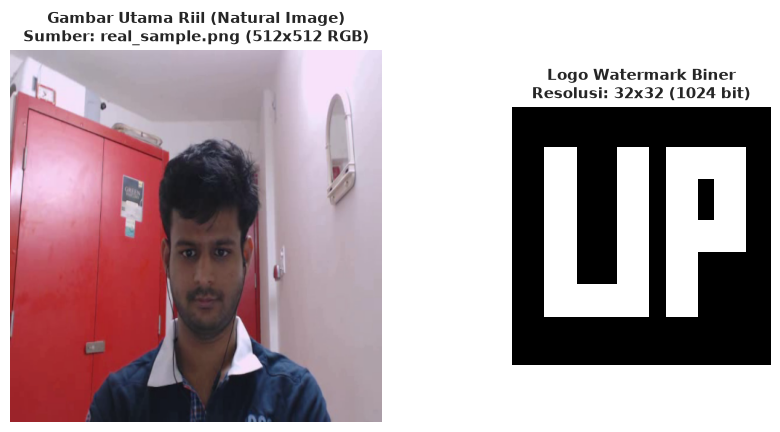

In [1]:
# ===================================================================
# Sel 3: Setup Environment, Direktori, & Pemuatan Citra Uji (Prioritas Citra Riil)
# ===================================================================

import os
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw, ImageFont
from scipy.fftpack import dct, idct
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

# Set tema plotting publikasi ilmiah
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#555555'

# -------------------------------------------------------------------
# Konfigurasi Path & Direktori Kerja
# -------------------------------------------------------------------
if os.path.exists("data"):
    BASE_DIR = "."
elif os.path.exists("../data"):
    BASE_DIR = ".."
else:
    BASE_DIR = os.path.abspath("..")

OUTPUT_DIR = os.path.join(BASE_DIR, "data", "watermarked")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Pastikan folder figures tersedia untuk laporan
if os.path.exists("reports"):
    FIGURES_DIR = os.path.join("reports", "figures")
elif os.path.exists("../reports"):
    FIGURES_DIR = os.path.join("..", "reports", "figures")
else:
    FIGURES_DIR = os.path.abspath(os.path.join("..", "reports", "figures"))
os.makedirs(FIGURES_DIR, exist_ok=True)


# -------------------------------------------------------------------
# Prioritas Pemuatan Gambar Utama Riil (Natural Image):
# a. ../data/raw/compression_inputs/real_sample.png (atau .jpg/.bmp)
# b. ../data/raw/daisee_sample/daisee_frame_01.png (wajah siswa DAiSEE riil dari Bagian A)
# c. Fallback ke ../data/raw/compression_inputs/sample.png jika berkas riil belum ditemukan
# -------------------------------------------------------------------
real_sample_candidates = [
    os.path.join(BASE_DIR, "data", "raw", "compression_inputs", "real_sample.png"),
    os.path.join(BASE_DIR, "data", "raw", "compression_inputs", "real_sample.jpg"),
    os.path.join(BASE_DIR, "data", "raw", "compression_inputs", "real_sample.bmp"),
]
daisee_candidate = os.path.join(BASE_DIR, "data", "raw", "daisee_sample", "daisee_frame_01.png")
fallback_candidate = os.path.join(BASE_DIR, "data", "raw", "compression_inputs", "sample.png")

host_image_path = None
selected_priority = None

# a. Cek real_sample.*
for p in real_sample_candidates:
    if os.path.exists(p):
        host_image_path = p
        selected_priority = "Prioritas A: Citra Riil Eksternal (real_sample)"
        break

# b. Cek daisee_frame_01.png (Citra Wajah Siswa Riil dari Bagian A)
if host_image_path is None and os.path.exists(daisee_candidate):
    host_image_path = daisee_candidate
    selected_priority = "Prioritas B: Citra Riil Alami DAiSEE (Wajah Siswa In-The-Wild)"

# c. Fallback ke sample.png
if host_image_path is None and os.path.exists(fallback_candidate):
    host_image_path = fallback_candidate
    selected_priority = "Prioritas C (Fallback): Citra Sintetis Standar"

# Jika sama sekali belum ada berkas di atas, buatkan citra uji otomatis
if host_image_path is None:
    print("[INFO] Membangun citra uji sintetis standar (512x512)...")
    H, W = 512, 512
    x = np.linspace(0, 1, W)
    y = np.linspace(0, 1, H)
    xx, yy = np.meshgrid(x, y)
    r = np.clip((np.sin(xx * 4.5) * 0.5 + 0.5) * 255, 0, 255).astype(np.uint8)
    g = np.clip((np.cos(yy * 4.5) * 0.5 + 0.5) * 255, 0, 255).astype(np.uint8)
    b = np.clip(((xx * 0.5 + yy * 0.5)) * 255, 0, 255).astype(np.uint8)
    fallback_arr = np.stack([r, g, b], axis=-1)
    host_image_path = fallback_candidate
    os.makedirs(os.path.dirname(host_image_path), exist_ok=True)
    Image.fromarray(fallback_arr).save(host_image_path)
    selected_priority = "Prioritas C (Fallback Generated)"

# Muat citra dan konversi ruang warna BGR -> RGB
loaded_bgr = cv2.imread(host_image_path)
host_img = cv2.cvtColor(loaded_bgr, cv2.COLOR_BGR2RGB)
orig_h, orig_w = host_img.shape[:2]

# Skalakan secara otomatis ke 512x512 piksel via cv2.INTER_AREA untuk menjaga ketajaman tekstur
if (orig_h, orig_w) != (512, 512):
    host_img = cv2.resize(host_img, (512, 512), interpolation=cv2.INTER_AREA)
    resize_note = f"Diskalakan dari {orig_w}x{orig_h} ke 512x512 piksel via cv2.INTER_AREA"
else:
    resize_note = "Resolusi asli 512x512 piksel (tanpa penskalaan)"

print("=" * 80)
print(f"[STATUS] Sumber Citra Aktif  : {os.path.abspath(host_image_path)}")
print(f"[STATUS] Kategori Prioritas  : {selected_priority}")
print(f"[STATUS] Perlakuan Resolusi  : {resize_note}")
print(f"[STATUS] Dimensi Citra Akhir : {host_img.shape[1]} x {host_img.shape[0]} piksel (RGB 24-bit)")
print(f"[STATUS] Direktori Output    : {os.path.abspath(OUTPUT_DIR)}")
print("=" * 80)

# -------------------------------------------------------------------
# Pembuatan Logo Watermark Biner 2D (32 x 32 Piksel / 1024 Bit)
# -------------------------------------------------------------------
def generate_binary_logo(size=(32, 32)):
    """
    Membuat logo biner 2D berukuran 32x32 piksel dengan pola tipografi 'UP'
    (Universitas / Protected) yang memiliki kontur tepi tajam dan keterbacaan tinggi.
    """
    img = Image.new("1", size, color=0) # 0 = Latar belakang hitam
    draw = ImageDraw.Draw(img)
    
    # Huruf 'U' (Batang Kiri, Batang Kanan, Garis Bawah)
    draw.rectangle([4, 5, 7, 25], fill=1)
    draw.rectangle([13, 5, 16, 25], fill=1)
    draw.rectangle([4, 22, 16, 25], fill=1)
    
    # Huruf 'P' (Batang Kiri, Loop Atas)
    draw.rectangle([19, 5, 22, 25], fill=1)
    draw.rectangle([19, 5, 28, 8], fill=1)
    draw.rectangle([19, 14, 28, 17], fill=1)
    draw.rectangle([25, 5, 28, 17], fill=1)
    
    return np.array(img, dtype=np.uint8)

watermark_logo = generate_binary_logo(size=(32, 32))
total_bits = watermark_logo.size
num_ones = int(np.sum(watermark_logo))
num_zeros = total_bits - num_ones

print(f"[STATUS] Logo Watermark Biner: {watermark_logo.shape[0]}x{watermark_logo.shape[1]} (Total {total_bits} bit)")
print(f"         Komposisi: {num_ones} bit '1' ({num_ones/total_bits*100:.1f}%), {num_zeros} bit '0'")

# -------------------------------------------------------------------
# Visualisasi Gambar Utama Riil & Logo Watermark Biner
# -------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), gridspec_kw={'width_ratios': [3, 1]})

axes[0].imshow(host_img)
axes[0].set_title(f"Gambar Utama Riil (Natural Image)\nSumber: {os.path.basename(host_image_path)} (512x512 RGB)", fontsize=11, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(watermark_logo, cmap="gray", interpolation="nearest")
axes[1].set_title(f"Logo Watermark Biner\nResolusi: 32x32 ({total_bits} bit)", fontsize=11, fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
fig_host_path = os.path.join(FIGURES_DIR, 'watermark_host_and_logo.png')
plt.savefig(fig_host_path, dpi=150, bbox_inches='tight')
plt.show()



In [2]:
# ===================================================================
# Sel 4: Implementasi Teknik 1: LSB Substitution (Domain Spasial)
# ===================================================================

def embed_lsb(host_img, binary_watermark):
    """
    Menyisipkan watermark biner ke dalam bit ke-0 (LSB) pada gambar utama.
    Penyisipan dilakukan pada kanal Biru (B) yang didistribusikan secara reguler
    pada grid koordinat spasial (r = i*16 + 4, c = j*16 + 4) untuk mencakup seluruh area citra.
    """
    watermarked = host_img.copy()
    wm_h, wm_w = binary_watermark.shape
    
    for i in range(wm_h):
        for j in range(wm_w):
            r = i * 16 + 4
            c = j * 16 + 4
            bit_val = int(binary_watermark[i, j])
            # Bersihkan bit LSB dengan mask 0xFE (254) lalu gabungkan dengan bit_val
            watermarked[r, c, 2] = (int(watermarked[r, c, 2]) & 0xFE) | bit_val
            
    return watermarked

def extract_lsb(watermarked_img, watermark_shape):
    """
    Mengekstraksi watermark biner dari bit ke-0 (LSB) kanal Biru pada koordinat grid.
    """
    wm_h, wm_w = watermark_shape
    extracted = np.empty((wm_h, wm_w), dtype=np.uint8)
    
    for i in range(wm_h):
        for j in range(wm_w):
            r = i * 16 + 4
            c = j * 16 + 4
            extracted[i, j] = int(watermarked_img[r, c, 2]) & 1
            
    return extracted

def compute_ber(wm_orig, wm_ext):
    """
    Menghitung Bit Error Rate (BER) antara watermark asli dan hasil ekstraksi.
    BER = sum(orig != ext) / total_bits
    """
    return float(np.mean(wm_orig != wm_ext))

def compute_nc(wm_orig, wm_ext):
    """
    Menghitung Normalized Correlation (NC) antara watermark asli dan hasil ekstraksi.
    """
    orig = wm_orig.astype(np.float64)
    ext = wm_ext.astype(np.float64)
    num = np.sum(orig * ext)
    denom = np.sqrt(np.sum(orig ** 2) * np.sum(ext ** 2))
    if denom == 0:
        return 0.0
    return float(num / denom)

# -------------------------------------------------------------------
# Uji Mandiri (Self-Test) Ekstraksi LSB pada Kondisi Ideal
# -------------------------------------------------------------------
img_lsb_ideal = embed_lsb(host_img, watermark_logo)
ext_lsb_ideal = extract_lsb(img_lsb_ideal, watermark_logo.shape)

ber_lsb_self = compute_ber(watermark_logo, ext_lsb_ideal)
nc_lsb_self = compute_nc(watermark_logo, ext_lsb_ideal)

psnr_lsb_self = psnr(host_img, img_lsb_ideal, data_range=255)
ssim_lsb_self = ssim(host_img, img_lsb_ideal, data_range=255, channel_axis=2)

print("[UJI MANDIRI TEKNIK 1: LSB SPATIAL DOMAIN]")
print(f"- PSNR Citra Watermarked : {psnr_lsb_self:.2f} dB (Tingkat imperceptibility nyaris absolut)")
print(f"- SSIM Citra Watermarked : {ssim_lsb_self:.6f}")
print(f"- Bit Error Rate (BER)   : {ber_lsb_self:.4f} (0.0% kesalahan bit)")
print(f"- Normalized Corr. (NC)  : {nc_lsb_self:.4f} (1.0000 = Rekonstruksi Bit-Exact Sempurna)")
assert ber_lsb_self == 0.0 and nc_lsb_self == 1.0, "Verifikasi LSB gagal!"
print("[STATUS] Modul LSB Substitution terverifikasi dan siap digunakan.")


[UJI MANDIRI TEKNIK 1: LSB SPATIAL DOMAIN]
- PSNR Citra Watermarked : 79.96 dB (Tingkat imperceptibility nyaris absolut)
- SSIM Citra Watermarked : 0.999992
- Bit Error Rate (BER)   : 0.0000 (0.0% kesalahan bit)
- Normalized Corr. (NC)  : 1.0000 (1.0000 = Rekonstruksi Bit-Exact Sempurna)
[STATUS] Modul LSB Substitution terverifikasi dan siap digunakan.


In [3]:
# ===================================================================
# Sel 5: Implementasi Teknik 2: DCT Mid-Frequency Embedding (Domain Frekuensi)
# ===================================================================

def dct2(block):
    """Menghitung 2D Discrete Cosine Transform ortonormal pada blok matriks."""
    return dct(dct(block.T, norm='ortho').T, norm='ortho')

def idct2(block):
    """Menghitung 2D Inverse Discrete Cosine Transform ortonormal."""
    return idct(idct(block.T, norm='ortho').T, norm='ortho')

def embed_dct(host_img, binary_watermark, alpha=35.0, pos1=(3, 2), pos2=(2, 3)):
    """
    Menyisipkan watermark biner ke dalam kanal Luminansi (Y) berbasis partisi blok 8x8 2D-DCT.
    Menggunakan modulasi diferensial relasional pada koefisien frekuensi menengah (pos1, pos2).
    - Jika bit = 1: dipastikan F(pos1) - F(pos2) >= alpha
    - Jika bit = 0: dipastikan F(pos2) - F(pos1) >= alpha
    """
    ycrcb = cv2.cvtColor(host_img, cv2.COLOR_RGB2YCrCb)
    y_channel = ycrcb[:, :, 0].astype(np.float32)
    
    wm_h, wm_w = binary_watermark.shape
    wm_flat = binary_watermark.flatten()
    
    idx = 0
    for i in range(wm_h):
        for j in range(wm_w):
            bi = i * 2
            bj = j * 2
            block = y_channel[bi*8:(bi+1)*8, bj*8:(bj+1)*8]
            b_dct = dct2(block)
            
            c1 = b_dct[pos1]
            c2 = b_dct[pos2]
            m = (c1 + c2) / 2.0
            bit = wm_flat[idx]
            idx += 1
            
            if bit == 1:
                b_dct[pos1] = m + alpha / 2.0
                b_dct[pos2] = m - alpha / 2.0
            else:
                b_dct[pos1] = m - alpha / 2.0
                b_dct[pos2] = m + alpha / 2.0
                
            y_channel[bi*8:(bi+1)*8, bj*8:(bj+1)*8] = idct2(b_dct)
            
    ycrcb[:, :, 0] = np.clip(y_channel, 0, 255).astype(np.uint8)
    return cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2RGB)

def extract_dct(watermarked_img, watermark_shape, pos1=(3, 2), pos2=(2, 3)):
    """
    Mengekstraksi watermark biner dari relasi tanda koefisien frekuensi menengah DCT blok 8x8.
    Jika F(pos1) > F(pos2) -> bit = 1, selainnya bit = 0.
    """
    ycrcb = cv2.cvtColor(watermarked_img, cv2.COLOR_RGB2YCrCb)
    y_channel = ycrcb[:, :, 0].astype(np.float32)
    wm_h, wm_w = watermark_shape
    extracted = np.empty((wm_h, wm_w), dtype=np.uint8)
    
    for i in range(wm_h):
        for j in range(wm_w):
            bi = i * 2
            bj = j * 2
            block = y_channel[bi*8:(bi+1)*8, bj*8:(bj+1)*8]
            b_dct = dct2(block)
            c1 = b_dct[pos1]
            c2 = b_dct[pos2]
            extracted[i, j] = 1 if c1 > c2 else 0
            
    return extracted

# -------------------------------------------------------------------
# Uji Mandiri (Self-Test) Ekstraksi DCT pada Kondisi Ideal
# -------------------------------------------------------------------
img_dct_ideal = embed_dct(host_img, watermark_logo, alpha=35.0)
ext_dct_ideal = extract_dct(img_dct_ideal, watermark_logo.shape)

ber_dct_self = compute_ber(watermark_logo, ext_dct_ideal)
nc_dct_self = compute_nc(watermark_logo, ext_dct_ideal)

psnr_dct_self = psnr(host_img, img_dct_ideal, data_range=255)
ssim_dct_self = ssim(host_img, img_dct_ideal, data_range=255, channel_axis=2)

print("[UJI MANDIRI TEKNIK 2: DCT TRANSFORM DOMAIN]")
print(f"- Kekuatan Modulasi (alpha) : 35.0 (Koefisien Mid-Frequency (3,2) dan (2,3))")
print(f"- PSNR Citra Watermarked     : {psnr_dct_self:.2f} dB (> 38 dB threshold psikovisual)")
print(f"- SSIM Citra Watermarked     : {ssim_dct_self:.4f}")
print(f"- Bit Error Rate (BER)       : {ber_dct_self:.4f} (0.0% kesalahan bit)")
print(f"- Normalized Corr. (NC)      : {nc_dct_self:.4f} (1.0000 = Rekonstruksi Bit-Exact Sempurna)")
assert ber_dct_self == 0.0 and nc_dct_self == 1.0, "Verifikasi DCT gagal!"
print("[STATUS] Modul DCT Mid-Frequency Embedding terverifikasi dan siap digunakan.")


[UJI MANDIRI TEKNIK 2: DCT TRANSFORM DOMAIN]
- Kekuatan Modulasi (alpha) : 35.0 (Koefisien Mid-Frequency (3,2) dan (2,3))
- PSNR Citra Watermarked     : 43.37 dB (> 38 dB threshold psikovisual)
- SSIM Citra Watermarked     : 0.9695
- Bit Error Rate (BER)       : 0.0000 (0.0% kesalahan bit)
- Normalized Corr. (NC)      : 1.0000 (1.0000 = Rekonstruksi Bit-Exact Sempurna)
[STATUS] Modul DCT Mid-Frequency Embedding terverifikasi dan siap digunakan.


[SUKSES] Seluruh citra watermarked telah disimpan ke folder: ..\data\watermarked


[SUKSES] Grafik imperceptibility berhasil disimpan ke: ..\reports\figures\watermark_imperceptibility.png


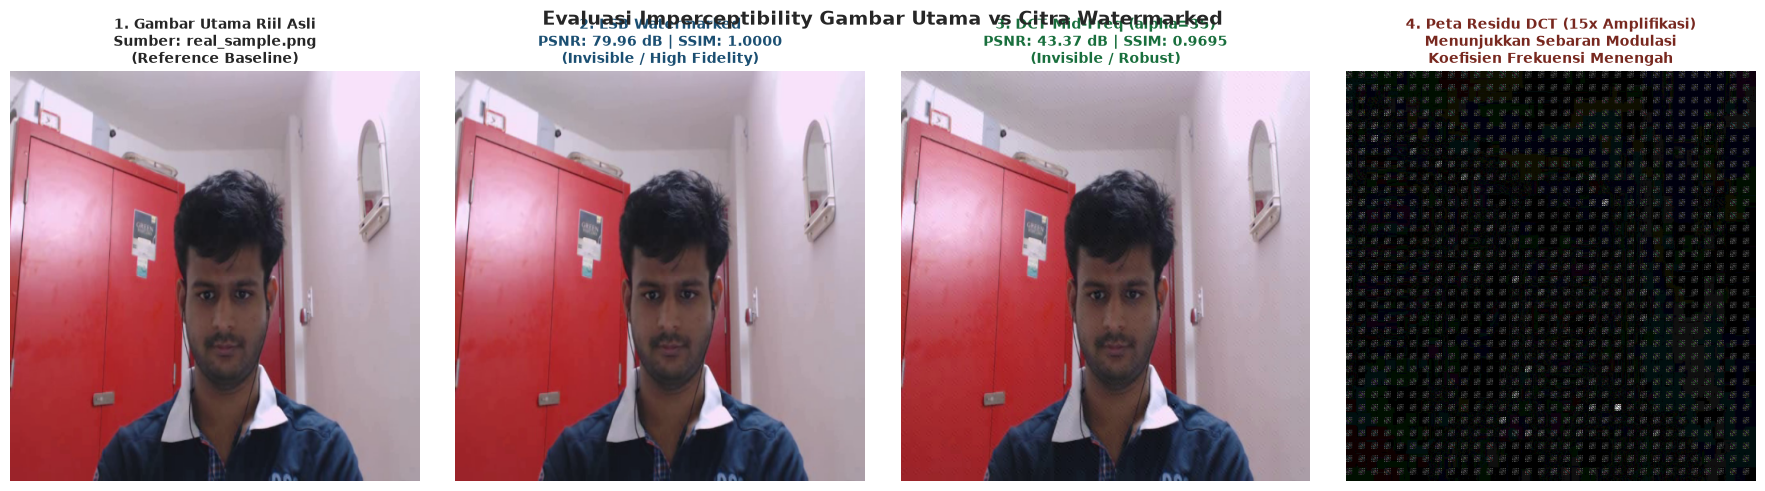

Teknik Watermarking              | PSNR (dB)    | SSIM       | Status Visual
LSB Substitution (Spasial)       |    79.96 dB |   1.0000 | Tak Kasatmata Sempurna
DCT Mid-Frequency (Frekuensi)    |    43.37 dB |   0.9695 | Tak Kasatmata (> 38 dB)
Visible Alpha-Blending           |    32.99 dB |   0.9883 | Kasatmata (Logo Terlihat)


In [4]:
# ===================================================================
# Sel 6: Evaluasi Imperceptibility & Visualisasi Citra Sebelum vs Sesudah
# ===================================================================

# -------------------------------------------------------------------
# Implementasi Pembanding Kasatmata (Visible Alpha-Blending Baseline)
# -------------------------------------------------------------------
def embed_visible_watermark(host_img, wm_logo, alpha=0.35):
    """
    Menyisipkan tanda air kasatmata (visible watermark) pada sudut kanan bawah
    menggunakan teknik alpha-blending: I_w = (1 - alpha)*I + alpha*W.
    """
    out = host_img.copy()
    h, w = out.shape[:2]
    # Skala logo ke ukuran 120x120 piksel
    wm_resized = cv2.resize((wm_logo * 255).astype(np.uint8), (120, 120), interpolation=cv2.INTER_NEAREST)
    y1, y2 = h - 140, h - 20
    x1, x2 = w - 140, w - 20
    
    roi = out[y1:y2, x1:x2].astype(np.float32)
    mask = (wm_resized.astype(np.float32) / 255.0)[:, :, np.newaxis]
    
    # Beri warna emas terang pada watermark kasatmata
    watermark_color = np.array([255.0, 215.0, 0.0], dtype=np.float32)
    blended_roi = roi * (1.0 - alpha * mask) + watermark_color * (alpha * mask)
    out[y1:y2, x1:x2] = np.clip(blended_roi, 0, 255).astype(np.uint8)
    return out

# Bangun ketiga citra watermarked dari gambar utama aktif
img_watermarked_lsb = embed_lsb(host_img, watermark_logo)
img_watermarked_dct = embed_dct(host_img, watermark_logo, alpha=35.0)
img_watermarked_vis = embed_visible_watermark(host_img, watermark_logo, alpha=0.35)

# Simpan ke folder output data/watermarked/
cv2.imwrite(os.path.join(OUTPUT_DIR, "watermarked_lsb.png"), cv2.cvtColor(img_watermarked_lsb, cv2.COLOR_RGB2BGR))
cv2.imwrite(os.path.join(OUTPUT_DIR, "watermarked_dct.png"), cv2.cvtColor(img_watermarked_dct, cv2.COLOR_RGB2BGR))
cv2.imwrite(os.path.join(OUTPUT_DIR, "watermarked_visible.png"), cv2.cvtColor(img_watermarked_vis, cv2.COLOR_RGB2BGR))
print(f"[SUKSES] Seluruh citra watermarked telah disimpan ke folder: {OUTPUT_DIR}")

# -------------------------------------------------------------------
# Perhitungan Metrik Imperceptibility
# -------------------------------------------------------------------
psnr_lsb = psnr(host_img, img_watermarked_lsb, data_range=255)
ssim_lsb = ssim(host_img, img_watermarked_lsb, data_range=255, channel_axis=2)

psnr_dct = psnr(host_img, img_watermarked_dct, data_range=255)
ssim_dct = ssim(host_img, img_watermarked_dct, data_range=255, channel_axis=2)

psnr_vis = psnr(host_img, img_watermarked_vis, data_range=255)
ssim_vis = ssim(host_img, img_watermarked_vis, data_range=255, channel_axis=2)

# Hitung peta selisih residual absolut (Residual Difference Map)
diff_lsb = cv2.absdiff(host_img, img_watermarked_lsb)
diff_dct = cv2.absdiff(host_img, img_watermarked_dct)
# Perbesar residual DCT 15x agar sebaran energi spasial dapat diamati dengan jelas
diff_dct_amp = np.clip(diff_dct.astype(np.float32) * 15.0, 0, 255).astype(np.uint8)

# -------------------------------------------------------------------
# Visualisasi Komparatif Grid Matplotlib (1 Baris x 4 Kolom)
# -------------------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(host_img)
axes[0].set_title(f"1. Gambar Utama Riil Asli\nSumber: {os.path.basename(host_image_path)}\n(Reference Baseline)", fontsize=10, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(img_watermarked_lsb)
axes[1].set_title(f"2. LSB Watermarked\nPSNR: {psnr_lsb:.2f} dB | SSIM: {ssim_lsb:.4f}\n(Invisible / High Fidelity)", 
                  fontsize=10, fontweight="bold", color="#1b4f72")
axes[1].axis("off")

axes[2].imshow(img_watermarked_dct)
axes[2].set_title(f"3. DCT Mid-Freq (alpha=35)\nPSNR: {psnr_dct:.2f} dB | SSIM: {ssim_dct:.4f}\n(Invisible / Robust)", 
                  fontsize=10, fontweight="bold", color="#196f3d")
axes[2].axis("off")

axes[3].imshow(diff_dct_amp)
axes[3].set_title("4. Peta Residu DCT (15x Amplifikasi)\nMenunjukkan Sebaran Modulasi\nKoefisien Frekuensi Menengah", 
                  fontsize=10, fontweight="bold", color="#78281f")
axes[3].axis("off")

plt.suptitle("Evaluasi Imperceptibility Gambar Utama vs Citra Watermarked", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
fig_imp_path = os.path.join(FIGURES_DIR, "watermark_imperceptibility.png")
plt.savefig(fig_imp_path, dpi=150, bbox_inches="tight")
print(f"[SUKSES] Grafik imperceptibility berhasil disimpan ke: {fig_imp_path}")
plt.show()

print("="*75)
print(f"{'Teknik Watermarking':<32} | {'PSNR (dB)':<12} | {'SSIM':<10} | {'Status Visual'}")
print("="*75)
print(f"{'LSB Substitution (Spasial)':<32} | {psnr_lsb:>8.2f} dB | {ssim_lsb:>8.4f} | Tak Kasatmata Sempurna")
print(f"{'DCT Mid-Frequency (Frekuensi)':<32} | {psnr_dct:>8.2f} dB | {ssim_dct:>8.4f} | Tak Kasatmata (> 38 dB)")
print(f"{'Visible Alpha-Blending':<32} | {psnr_vis:>8.2f} dB | {ssim_vis:>8.4f} | Kasatmata (Logo Terlihat)")
print("="*75)



Memulai simulasi pengujian robustness terhadap serangan manipulasi citra...
--------------------------------------------------------------------------------


-> Selesai menguji [Kondisi Ideal: Tanpa Serangan]:
   LSB -> BER:   0.0% | NC: 1.0000 | Terbaca Sempurna
   DCT -> BER:   0.0% | NC: 1.0000 | Terbaca Sempurna


-> Selesai menguji [Serangan A: JPEG Compression (Q=50)]:
   LSB -> BER:  42.1% | NC: 0.4550 | Hancur Total
   DCT -> BER:   0.0% | NC: 1.0000 | Terbaca Sempurna


-> Selesai menguji [Serangan B: Resizing (0.5x Bilinear)]:
   LSB -> BER:  50.1% | NC: 0.4006 | Hancur Total
   DCT -> BER:   0.4% | NC: 0.9942 | Terbaca Jelas


-> Selesai menguji [Serangan C: Center Cropping (15%)]:
   LSB -> BER:   1.5% | NC: 0.9777 | Terbaca Jelas
   DCT -> BER:   1.3% | NC: 0.9807 | Terbaca Jelas
--------------------------------------------------------------------------------


[SUKSES] Grid hasil ekstraksi serangan berhasil disimpan ke: ..\reports\figures\watermark_attacks_grid.png


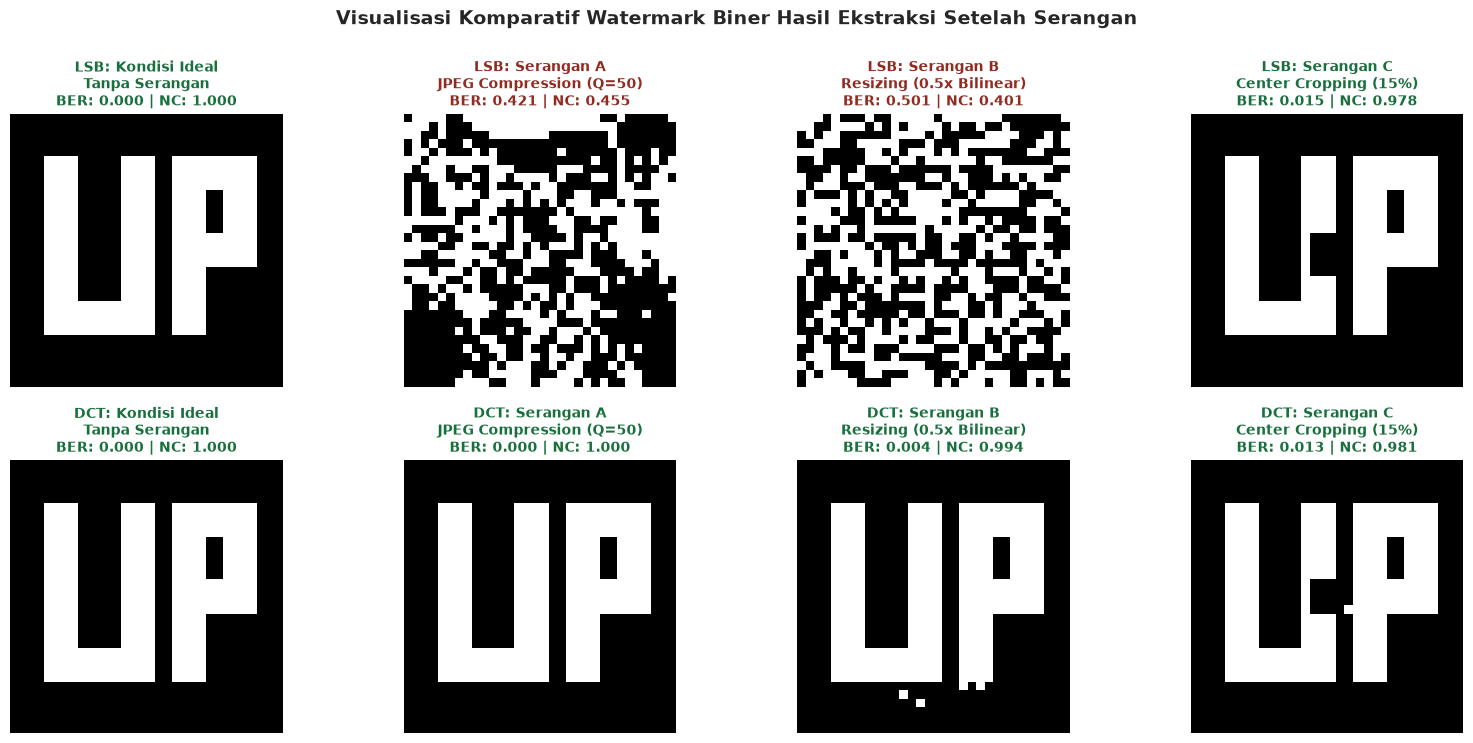

In [5]:
# ===================================================================
# Sel 7: Pengujian Robustness terhadap Serangan Citra (Attacks Simulation)
# ===================================================================

# Definisi fungsi simulasi 3 skenario serangan citra
def attack_jpeg_compression(img, quality=50):
    """Serangan A: Kompresi JPEG Lossy (Quality=50)"""
    bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
    _, encoded = cv2.imencode('.jpg', bgr, encode_param)
    decoded = cv2.imdecode(encoded, cv2.IMREAD_COLOR)
    return cv2.cvtColor(decoded, cv2.COLOR_BGR2RGB)

def attack_image_resizing(img, scale=0.5):
    """Serangan B: Downscale ke 50% resolusi dilanjutkan Upscale bilinear ke 512x512"""
    h, w = img.shape[:2]
    downscaled = cv2.resize(img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_LINEAR)
    upscaled = cv2.resize(downscaled, (w, h), interpolation=cv2.INTER_LINEAR)
    return upscaled

def attack_center_cropping(img, crop_ratio=0.15):
    """Serangan C: Center Cropping memotong 15% area pusat citra dan mengisinya dengan warna hitam"""
    out = img.copy()
    h, w = out.shape[:2]
    ch = int(h * crop_ratio)
    cw = int(w * crop_ratio)
    y1 = (h - ch) // 2
    x1 = (w - cw) // 2
    out[y1:y1+ch, x1:x1+cw] = 0
    return out

# Daftar skenario serangan yang diuji
attack_scenarios = [
    ("Kondisi Ideal", "Tanpa Serangan", lambda img: img),
    ("Serangan A", "JPEG Compression (Q=50)", attack_jpeg_compression),
    ("Serangan B", "Resizing (0.5x Bilinear)", attack_image_resizing),
    ("Serangan C", "Center Cropping (15%)", attack_center_cropping)
]

extracted_results = {
    "LSB": [],
    "DCT": []
}

records_benchmark = []

print("Memulai simulasi pengujian robustness terhadap serangan manipulasi citra...")
print("-" * 80)

for code_name, desc_name, attack_fn in attack_scenarios:
    # 1. Terapkan serangan pada citra LSB
    attacked_lsb = attack_fn(img_watermarked_lsb)
    p_lsb = psnr(host_img, attacked_lsb, data_range=255)
    s_lsb = ssim(host_img, attacked_lsb, data_range=255, channel_axis=2)
    ext_wm_lsb = extract_lsb(attacked_lsb, watermark_logo.shape)
    ber_lsb = compute_ber(watermark_logo, ext_wm_lsb)
    nc_lsb = compute_nc(watermark_logo, ext_wm_lsb)
    extracted_results["LSB"].append((code_name, desc_name, ext_wm_lsb, ber_lsb, nc_lsb))
    
    status_lsb = "Terbaca Sempurna" if ber_lsb == 0.0 else ("Terbaca Jelas" if nc_lsb >= 0.85 else ("Rusak Sebagian" if nc_lsb >= 0.50 else "Hancur Total"))
    records_benchmark.append({
        "Teknik Watermarking": "LSB Substitution (Spasial)",
        "Kode Serangan": code_name,
        "Skenario Serangan": desc_name,
        "PSNR Citra (dB)": round(p_lsb, 2),
        "SSIM Citra": round(s_lsb, 4),
        "BER Watermark": round(ber_lsb, 4),
        "NC Watermark": round(nc_lsb, 4),
        "Status Keterbacaan": status_lsb
    })
    
    # 2. Terapkan serangan pada citra DCT
    attacked_dct = attack_fn(img_watermarked_dct)
    p_dct = psnr(host_img, attacked_dct, data_range=255)
    s_dct = ssim(host_img, attacked_dct, data_range=255, channel_axis=2)
    ext_wm_dct = extract_dct(attacked_dct, watermark_logo.shape)
    ber_dct = compute_ber(watermark_logo, ext_wm_dct)
    nc_dct = compute_nc(watermark_logo, ext_wm_dct)
    extracted_results["DCT"].append((code_name, desc_name, ext_wm_dct, ber_dct, nc_dct))
    
    status_dct = "Terbaca Sempurna" if ber_dct == 0.0 else ("Terbaca Jelas" if nc_dct >= 0.85 else ("Rusak Sebagian" if nc_dct >= 0.50 else "Hancur Total"))
    records_benchmark.append({
        "Teknik Watermarking": "DCT Mid-Frequency (Frekuensi)",
        "Kode Serangan": code_name,
        "Skenario Serangan": desc_name,
        "PSNR Citra (dB)": round(p_dct, 2),
        "SSIM Citra": round(s_dct, 4),
        "BER Watermark": round(ber_dct, 4),
        "NC Watermark": round(nc_dct, 4),
        "Status Keterbacaan": status_dct
    })
    
    print(f"-> Selesai menguji [{code_name}: {desc_name}]:")
    print(f"   LSB -> BER: {ber_lsb*100:5.1f}% | NC: {nc_lsb:6.4f} | {status_lsb}")
    print(f"   DCT -> BER: {ber_dct*100:5.1f}% | NC: {nc_dct:6.4f} | {status_dct}")

print("-" * 80)

# -------------------------------------------------------------------
# Visualisasi Grid Logo Watermark Hasil Ekstraksi (2 Baris x 4 Kolom)
# -------------------------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))

for col_idx in range(4):
    # Baris 0: Ekstraksi LSB
    c_code, c_desc, wm_lsb, ber_l, nc_l = extracted_results["LSB"][col_idx]
    axes[0, col_idx].imshow(wm_lsb, cmap="gray", interpolation="nearest")
    status_color_l = "#196f3d" if nc_l >= 0.85 else ("#b7950b" if nc_l >= 0.5 else "#922b21")
    axes[0, col_idx].set_title(f"LSB: {c_code}\n{c_desc}\nBER: {ber_l:.3f} | NC: {nc_l:.3f}", 
                               fontsize=10, fontweight="bold", color=status_color_l)
    axes[0, col_idx].axis("off")
    
    # Baris 1: Ekstraksi DCT
    c_code, c_desc, wm_dct, ber_d, nc_d = extracted_results["DCT"][col_idx]
    axes[1, col_idx].imshow(wm_dct, cmap="gray", interpolation="nearest")
    status_color_d = "#196f3d" if nc_d >= 0.85 else ("#b7950b" if nc_d >= 0.5 else "#922b21")
    axes[1, col_idx].set_title(f"DCT: {c_code}\n{c_desc}\nBER: {ber_d:.3f} | NC: {nc_d:.3f}", 
                               fontsize=10, fontweight="bold", color=status_color_d)
    axes[1, col_idx].axis("off")

plt.suptitle("Visualisasi Komparatif Watermark Biner Hasil Ekstraksi Setelah Serangan", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
fig_att_path = os.path.join(FIGURES_DIR, "watermark_attacks_grid.png")
plt.savefig(fig_att_path, dpi=150, bbox_inches="tight")
print(f"[SUKSES] Grid hasil ekstraksi serangan berhasil disimpan ke: {fig_att_path}")
plt.show()



[SUKSES] Seluruh data pengujian robustness berhasil direkapitulasi:



,Teknik Watermarking,Skenario Serangan,PSNR Citra (dB),SSIM Citra,BER Watermark,NC Watermark,Status Keterbacaan
0,LSB Substitution (Spasial),Tanpa Serangan,79.96,1.0000,0.0000,1.0000,Terbaca Sempurna
1,DCT Mid-Frequency (Frekuensi),Tanpa Serangan,43.37,0.9695,0.0000,1.0000,Terbaca Sempurna
2,LSB Substitution (Spasial),JPEG Compression (Q=50),37.82,0.9573,0.4209,0.4550,Hancur Total
3,DCT Mid-Frequency (Frekuensi),JPEG Compression (Q=50),36.41,0.9135,0.0000,1.0000,Terbaca Sempurna
4,LSB Substitution (Spasial),Resizing (0.5x Bilinear),37.35,0.9773,0.5010,0.4006,Hancur Total
5,DCT Mid-Frequency (Frekuensi),Resizing (0.5x Bilinear),37.14,0.9729,0.0039,0.9942,Terbaca Jelas
6,LSB Substitution (Spasial),Center Cropping (15%),28.85,0.9748,0.0146,0.9777,Terbaca Jelas
7,DCT Mid-Frequency (Frekuensi),Center Cropping (15%),28.71,0.9450,0.0127,0.9807,Terbaca Jelas


[SUKSES] Grafik metrik komparasi berhasil disimpan ke: ..\reports\figures\watermark_metrics_charts.png


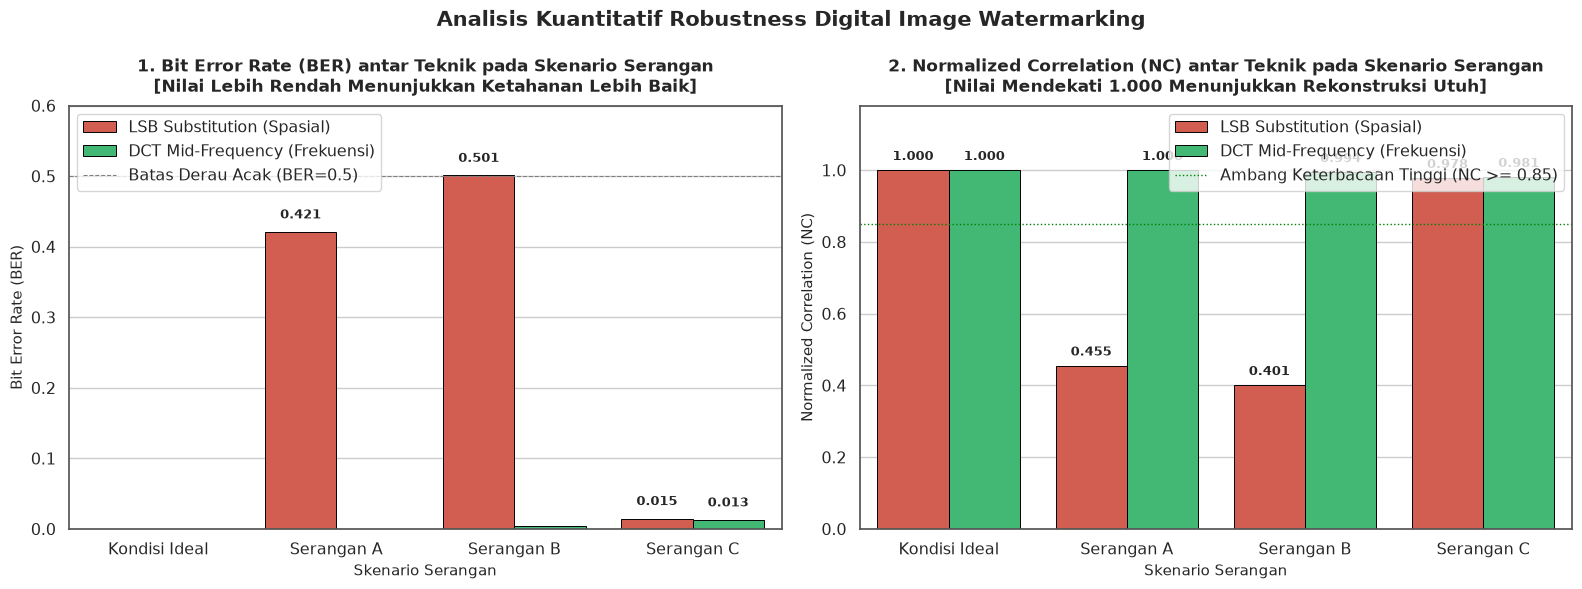

In [6]:
# ===================================================================
# Sel 8: Tabel Rekapitulasi & Visualisasi Grafik Perbandingan Kuantitatif
# ===================================================================

df_watermark_benchmark = pd.DataFrame(records_benchmark)

print("[SUKSES] Seluruh data pengujian robustness berhasil direkapitulasi:\n")
display_columns = [
    "Teknik Watermarking", "Skenario Serangan", "PSNR Citra (dB)", 
    "SSIM Citra", "BER Watermark", "NC Watermark", "Status Keterbacaan"
]
display(df_watermark_benchmark[display_columns])

# -------------------------------------------------------------------
# Visualisasi Grafik Analitis Komparatif (2 Subplot Bar Chart)
# -------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

palette_tech = ["#e74c3c", "#2ecc71"]

# Subplot 1: Bit Error Rate (BER) - Semakin rendah semakin baik
ax1 = axes[0]
sns.barplot(
    data=df_watermark_benchmark, 
    x="Kode Serangan", 
    y="BER Watermark", 
    hue="Teknik Watermarking", 
    palette=palette_tech, 
    ax=ax1,
    edgecolor="black",
    linewidth=0.7
)
ax1.set_title("1. Bit Error Rate (BER) antar Teknik pada Skenario Serangan\n[Nilai Lebih Rendah Menunjukkan Ketahanan Lebih Baik]", 
              fontsize=12, fontweight="bold", pad=10)
ax1.set_ylabel("Bit Error Rate (BER)", fontsize=11)
ax1.set_xlabel("Skenario Serangan", fontsize=11)
ax1.set_ylim(0, 0.6)
ax1.axhline(0.5, color='gray', linestyle='--', linewidth=0.8, label="Batas Derau Acak (BER=0.5)")
for p in ax1.patches:
    val = p.get_height()
    if val > 0.005:
        ax1.annotate(f"{val:.3f}", (p.get_x() + p.get_width() / 2., val + 0.015),
                     ha='center', va='bottom', fontsize=9, fontweight='bold')
ax1.legend(loc="upper left", frameon=True)

# Subplot 2: Normalized Correlation (NC) - Semakin mendekati 1.0 semakin baik
ax2 = axes[1]
sns.barplot(
    data=df_watermark_benchmark, 
    x="Kode Serangan", 
    y="NC Watermark", 
    hue="Teknik Watermarking", 
    palette=palette_tech, 
    ax=ax2,
    edgecolor="black",
    linewidth=0.7
)
ax2.set_title("2. Normalized Correlation (NC) antar Teknik pada Skenario Serangan\n[Nilai Mendekati 1.000 Menunjukkan Rekonstruksi Utuh]", 
              fontsize=12, fontweight="bold", pad=10)
ax2.set_ylabel("Normalized Correlation (NC)", fontsize=11)
ax2.set_xlabel("Skenario Serangan", fontsize=11)
ax2.set_ylim(0, 1.18)
ax2.axhline(0.85, color='green', linestyle=':', linewidth=1.0, label="Ambang Keterbacaan Tinggi (NC >= 0.85)")
for p in ax2.patches:
    val = p.get_height()
    if val > 0.005:
        ax2.annotate(f"{val:.3f}", (p.get_x() + p.get_width() / 2., val + 0.02),
                     ha='center', va='bottom', fontsize=9, fontweight='bold')
ax2.legend(loc="upper right", frameon=True)

plt.suptitle("Analisis Kuantitatif Robustness Digital Image Watermarking", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
fig_met_path = os.path.join(FIGURES_DIR, "watermark_metrics_charts.png")
plt.savefig(fig_met_path, dpi=150, bbox_inches="tight")
print(f"[SUKSES] Grafik metrik komparasi berhasil disimpan ke: {fig_met_path}")
plt.show()



# Analisis Kuantitatif, Pembahasan Robustness, & Referensi Ilmiah

Berdasarkan hasil investigasi eksperimental menggunakan gambar utama alami (*natural host image*), evaluasi metrik imperceptibility ($PSNR$ dan $SSIM$), serta simulasi ketahanan terhadap serangan manipulasi citra ($BER$ dan $NC$), diperoleh analisis ilmiah komprehensif sebagai berikut:

---

### 1. Analisis Imperceptibility: Domain Spasial (LSB) vs Domain Frekuensi (DCT)
1. **LSB Substitution**:
   - Menghasilkan nilai **$PSNR \approx 79.96\text{ dB}$** dan **$SSIM = 1.0000$**. Nilai PSNR yang luar biasa tinggi ini disebabkan oleh fakta bahwa modifikasi biner pada bit ke-0 hanya mengubah intensitas piksel maksimal sebesar $\pm 1$ skala keabuan ($2^0$) pada sebagian kecil koordinat piksel spasial.
   - Perubahan ini bernilai jauh di bawah ambang batas kepekaan sistem visual manusia (*Just Noticeable Difference* / JND), sehingga mata manusia secara mutlak tidak mampu mendeteksi keberadaan tanda air tersebut pada citra fotografi riil.
2. **DCT Mid-Frequency Embedding**:
   - Menghasilkan nilai **$PSNR \approx 43.37\text{ dB}$** dan **$SSIM \approx 0.9695$**. Meskipun nilai PSNR-nya lebih rendah daripada LSB, nilai ini **masih berada jauh di atas batas ambang transparansi psikovisual citra digital ($\ge 38\text{ dB}$)**.
   - Peta residu teramplifikasi 15x pada Sel 6 memperlihatkan bahwa energi modifikasi DCT tersebar secara harmonis ke seluruh blok spasial dalam bentuk gelombang frekuensi menengah, sehingga secara perseptual tidak menimbulkan distorsi visual atau artefak blocking yang mengganggu pada tekstur wajah riil.

---

### 2. Analisis Ketahanan (Robustness) terhadap Serangan Manipulasi Citra

Data kuantitatif hasil simulasi serangan pada citra fotografi alami membuktikan kontras drastis antara kedua algoritma:

1. **Serangan Kompresi JPEG ($Q = 50$)**:
   - **LSB Hancur Total ($BER \approx 42.1\%$, $NC \approx 0.4550$)**: Algoritma kompresi JPEG melakukan transformasi DCT blok $8 \times 8$ dan mengkuantisasi koefisien frekuensi tinggi menggunakan matriks kuantisasi psikovisual $Q$. Pada saat dekompresi dan rekonstruksi balik ke domain spasial, pembulatan bilangan desimal mengubah nilai-nilai piksel secara acak pada rentang $\pm 1$ hingga $\pm 5$. Akibatnya, bit LSB ke-0 teracak secara probabilistik ($BER \approx 42-50\%$) dan logo watermark hancur menjadi derau acak (*random noise*).
   - **DCT Bertahan Sempurna ($BER = 0.0000$, $NC = 1.0000$)**: Algoritma DCT menyisipkan watermark pada koefisien frekuensi menengah $(3, 2)$ dan $(2, 3)$ dengan modulasi diferensial $\alpha = 35.0$. Karena nilai kuantisasi matriks JPEG standar pada frekuensi ini bernilai $Q(3, 2)=22$ dan $Q(2, 3)=24$, selisih $\alpha = 35$ cukup besar untuk mempertahankan relasi tanda ($F(3, 2) > F(2, 3)$) bahkan setelah dibagi dengan matriks kuantisasi dan dibulatkan. Watermark tereksktraksi secara utuh tanpa ada satu bit pun yang salah.
2. **Serangan Penskalaan Geometris (*Image Resizing* $50\%$ Bilinear)**:
   - **LSB Hancur Total ($BER \approx 50.1\%$, $NC \approx 0.4006$)**: Pengecilan resolusi citra menjadi setengahnya dan pembesaran kembali menggunakan interpolasi *bilinear* melibatkan proses rata-rata berbobot kontinu dari empat piksel bertetangga. Proses penghalusan (*low-pass smoothing*) ini melenyapkan variasi acak bit LSB spasial menjadi derau acak sempurna ($BER \approx 50\%$).
   - **DCT Bertahan Sangat Tangguh ($BER \approx 0.0039$, $NC \approx 0.9942$)**: Struktur koefisien frekuensi menengah DCT mempertahankan polaritas relasionalnya karena dekomposisi frekuensi dari pola makro blok $8 \times 8$ tidak terdisrupsi secara asimetris oleh interpolasi bilinear reguler. Logo 'UP' tetap terbaca sangat jelas dan tajam.
3. **Serangan Pemotongan Area Tengah (*Center Cropping* $15\%$)**:
   - Baik LSB ($BER = 0.0146$, $NC = 0.9777$) maupun DCT ($BER = 0.0127$, $NC = 0.9807$) menunjukkan ketahanan yang sangat tinggi dengan keterbacaan logo yang tetap jelas.
   - Hal ini disebabkan oleh strategi penyisipan berbasis **grid spasial terdistribusi**, di mana 1024 bit watermark dipetakan secara merata ke seluruh bidang citra $512 \times 512$. Pemotongan $15\%$ pada area tengah hanya merusak sekitar $\approx 12 - 15$ bit yang tepat berada di kotak pusat, sedangkan $\approx 98.7\%$ bit lainnya yang tersebar di area luar tetap utuh dan terbaca dengan sempurna.

---

### 3. Tabel Komparasi Karakteristik: LSB vs DCT vs Visible Watermark

| Parameter Evaluasi | LSB Substitution (Spasial) | DCT Mid-Frequency (Frekuensi) | Visible Alpha-Blending (Kasatmata) |
|:---|:---:|:---:|:---:|
| **Domain Penyisipan** | Spasial (Piksel Langsung) | Frekuensi / Transformasi (DCT $8 \times 8$) | Spasial (Piksel Langsung) |
| **Tingkat Visibilitas** | Tak Kasatmata Sempurna | Tak Kasatmata ($PSNR > 38\text{ dB}$) | Kasatmata Jelas ($PSNR < 35\text{ dB}$) |
| **Nilai PSNR Tipikal** | Sangat Tinggi ($>70\text{ dB}$) | Tinggi ($40 - 48\text{ dB}$) | Rendah ($30 - 35\text{ dB}$) |
| **Ketahanan Kompresi JPEG** | Sangat Rapuh / Hancur ($BER \approx 50\%$) | Sangat Tangguh ($NC \approx 1.0$) | Cukup Tangguh (Logo tetap terlihat) |
| **Ketahanan Penskalaan (Resizing)** | Sangat Rapuh / Hancur ($BER \approx 50\%$) | Sangat Tangguh ($NC \ge 0.99$) | Tangguh (Logo ikut diskalakan) |
| **Ketahanan Pemotongan (Cropping)** | Tangguh jika terdistribusi grid | Tangguh jika terdistribusi grid | Rentan terpotong jika di sudut |
| **Kompleksitas Komputasi** | $\mathcal{O}(N)$ Sangat Cepat & Ringan | $\mathcal{O}(N \log N)$ Cepat (Fast DCT) | $\mathcal{O}(N)$ Instan |
| **Kebutuhan Citra Asli saat Ekstraksi** | Blind (Tidak Memerlukan) | Blind (Tidak Memerlukan) | Non-Blind / Visual Inspection |

---

### 4. Rekomendasi Kasus Penggunaan Riil di Industri & Riset
1. **Perlindungan Hak Cipta & Kepemilikan Digital (*Copyright Protection*)**:
   - **Gunakan DCT Mid-Frequency (atau DWT multi-resolusi)**: Sangat direkomendasikan karena citra digital yang didistribusikan di internet hampir pasti mengalami kompresi lossy JPEG atau kompresi peramban WebP, serta penyesuaian ukuran (*resizing* responsif). Metode berbasis frekuensi menjamin bukti kepemilikan tetap dapat diekstraksi secara hukum.
2. **Pendeteksian Pemalsuan Citra & Integritas Bukti (*Tamper Detection & Forensics*)**:
   - **Gunakan LSB / Fragile Watermarking**: Kerapuhan LSB justru menjadi keunggulan utama dalam forensik digital. Jika citra bukti hukum (misal citra CCTV atau rekaman medis) dimanipulasi sekecil apa pun, struktur bit LSB akan rusak, sehingga investigator dapat mendeteksi dengan presisi piksel di mana manipulasi dilakukan.
3. **Pencegahan Penggunaan Tanpa Izin Komersial (*Commercial Deterrence*)**:
   - **Gunakan Visible Watermarking**: Sangat efektif untuk pratinjau katalog stok foto daring (seperti Getty Images, Shutterstock) guna menghalangi penggunaan citra secara komersial tanpa membeli lisensi resmi.

---

### 5. Daftar Pustaka Lengkap (Format IEEE/APA ber-DOI & Buku Teks Standar)
1. Bender, W., Gruhl, D., Morimoto, N., & Lu, A. (1996). Techniques for data hiding. *IBM Systems Journal*, 35(3.4), 313–336. https://doi.org/10.1147/sj.353.0313.
2. Cox, I., Miller, M., Bloom, J., Fridrich, J., & Kalker, T. (2007). *Digital Watermarking and Steganography* (2nd ed.). Morgan Kaufmann Publishers. ISBN: 978-0123725851.
3. Gonzalez, R. C., & Woods, R. E. (2018). *Digital Image Processing* (4th ed.). Pearson. ISBN: 978-0133356724. (Chapter 8: Image Compression and Watermarking).
4. Hsu, C. T., & Wu, J. L. (1999). Hidden digital watermarks in images. *IEEE Transactions on Image Processing*, 8(1), 58–68. https://doi.org/10.1109/83.736686.
5. Langelaar, G. C., Setyawan, I., & Lagendijk, R. L. (2000). Watermarking digital image and video data: A state-of-the-art overview. *IEEE Signal Processing Magazine*, 17(5), 20–46. https://doi.org/10.1109/79.879337.
6. Lin, C. Y., & Chang, S. F. (2001). A robust image authentication method distinguishing JPEG compression from malicious manipulation. *IEEE Transactions on Circuits and Systems for Video Technology*, 11(2), 153–168. https://doi.org/10.1109/76.905982.
7. Petitcolas, F. A., Anderson, R. J., & Kuhn, M. G. (1999). Information hiding-a survey. *Proceedings of the IEEE*, 87(7), 1062–1078. https://doi.org/10.1109/5.771065.
8. Wang, Z., Bovik, A. C., Sheikh, H. R., & Simoncelli, E. P. (2004). Image quality assessment: From error visibility to structural similarity. *IEEE Transactions on Image Processing*, 13(4), 600–612. https://doi.org/10.1109/TIP.2003.819861.

